# 01 · Data

What do twenty years of daily US stock-market returns look like, and how far are their tails from a Gaussian?

| Reads | Produces | Running time |
|---|---|---|
| `data/F-F_Research_Data_Factors_daily.csv` (downloaded only if missing) | `data/returns.csv`<br>`../report/figures/data_overview.pdf` (report, Section 2)<br>`../report/tables/data_summary.tex` (report, appendix) | a few seconds |

**01 Data** → 02 Model and sampler → 03 Validation → 04 Posterior → 05 Risk → 06 Checks

In [1]:
# Setup: libraries, our shared functions and the constants of this notebook
import io
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from tools import COLOR_DATA, COLOR_GAUSS, save_figure, save_table, set_style

# Source: Fama/French 3 Factors (daily), Kenneth R. French Data Library, built from CRSP
URL = ("https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/"
       "F-F_Research_Data_Factors_daily_CSV.zip")
RAW_FILE = Path("data/F-F_Research_Data_Factors_daily.csv")
RETURNS_FILE = Path("data/returns.csv")

# Our window: 20 full years, including the 2008 financial crisis and the March 2020 crash
START, END = "2006-01-01", "2025-12-31"

# This notebook draws no random numbers, so it needs no seed
set_style()

## 1. The raw file

We use the daily **US stock market return** of the Kenneth R. French Data Library: the value-weighted return of all US firms listed on the NYSE, AMEX and NASDAQ, built from the CRSP database. The library revises its files every month, so we keep the snapshot we downloaded on 1 November 2026 in `data/`, and download the file only if it is missing.

In [2]:
# Download the zip and extract the CSV, only if our snapshot is missing
# DECISION: never overwrite the snapshot, so that a revision of the source cannot change our numbers
if not RAW_FILE.exists():
    RAW_FILE.parent.mkdir(exist_ok=True)
    with urllib.request.urlopen(URL) as response:
        archive = zipfile.ZipFile(io.BytesIO(response.read()))
    archive.extract(RAW_FILE.name, RAW_FILE.parent)

# The first line of the file says which version of the CRSP database it was built from
print(RAW_FILE.read_text().splitlines()[0])

This file was created by using the 202609 CRSP database.


In [3]:
# Read the file: 4 lines of notes, a header, one row per day (date as YYYYMMDD), a copyright line
raw = pd.read_csv(RAW_FILE, skiprows=4, index_col=0)
raw.index = pd.to_datetime(raw.index.astype(str), format="%Y%m%d", errors="coerce")
raw = raw[raw.index.notna()]  # the copyright line has no date: we drop it
raw.tail(3)

,Mkt-RF,SMB,HML,RF
2026-09-28,-0.82,0.31,-0.50,0.01
2026-09-29,-0.21,-0.01,-0.50,0.01
2026-09-30,-0.26,0.32,-0.88,0.01


## 2. Daily log-returns

The file gives, in percent, the market return in excess of the risk-free rate (`Mkt-RF`) and the risk-free rate (`RF`). The market return of day $t$ is their sum, $R_t = (\text{Mkt-RF}_t + \text{RF}_t)/100$, and we work with the **log-return**

$$y_t = \log(1 + R_t), \qquad t = 1, \dots, n,$$

because log-returns add up over days. The **loss** of day $t$ is $L_t = -y_t$: it is positive when the market falls.

In [4]:
# Market return in decimals, then the log-returns over our window
# ASSUMPTION: market return = Mkt-RF + RF, the Fama-French definition
# ASSUMPTION: the source rounds returns to 0.01%, negligible next to daily moves of about 1%
R = (raw["Mkt-RF"] + raw["RF"]) / 100
y = np.log1p(R).loc[START:END]
y.name = "y"
y.index.name = "date"
n = len(y)

In [5]:
# Checks: no missing value (the library writes them as -99.99), dates in order, no duplicate day
assert y.notna().all()
assert (raw.loc[START:END, ["Mkt-RF", "RF"]] > -99).all().all()
assert y.index.is_monotonic_increasing and y.index.is_unique

# Save the log-returns, in decimals, for the next notebooks
y.to_csv(RETURNS_FILE)
print(f"n = {n:,} trading days, from {y.index[0]:%d %B %Y} to {y.index[-1]:%d %B %Y}")

n = 5,031 trading days, from 03 January 2006 to 31 December 2025


## 3. A first look at the returns

Before writing a model, we compare the data with the simplest one: a **Gaussian** with the same mean $\bar y$ and standard deviation $s$. Two numbers describe the tails:

- the number of days further than 4 standard deviations from the mean, against the number the Gaussian expects, $2\,n\,\Phi(-4)$;
- the worst and best days, against the level the Gaussian reaches on one day in $n$, $\bar y \mp s\,\Phi^{-1}(1 - 1/n)$: the most extreme day it expects over the whole window.

From here on, returns are shown in percent.

> **[COURSE]** Chebyshev's inequality: Preliminaries, Sec. 5.2, Theorem 2 (p. 5).
> $P(|X - \mu| \ge x) \le \sigma^2 / x^2$ for any distribution with a finite variance: at most $1/16$ of the days can lie beyond 4 sd.

In [6]:
# Summary of the data, with the Gaussian reference (same mean and sd) where there is one
# DECISION: no skewness or kurtosis: with tails this heavy these moments may not exist (notebook 04),
# so their sample values are unstable; counting extreme days carries the same message reliably
y_pct = 100 * y
mean, sd = y_pct.mean(), y_pct.std()
beyond_4sd = int((abs(y_pct - mean) > 4 * sd).sum())
expected_4sd = 2 * n * stats.norm.cdf(-4)
once_in_n = sd * stats.norm.ppf(1 - 1 / n)  # distance from the mean reached on one day in n

rows = {
    "Trading days":           [f"{n:,}", ""],
    "Mean (%)":               [round(mean, 3), ""],
    "Standard deviation (%)": [round(sd, 3), ""],
    "Worst day (%)":          [round(y_pct.min(), 2), round(mean - once_in_n, 2)],
    "Best day (%)":           [round(y_pct.max(), 2), round(mean + once_in_n, 2)],
    "Days beyond 4 sd":       [beyond_4sd, round(expected_4sd, 2)],
}
summary = pd.DataFrame.from_dict(rows, orient="index", columns=["Data", "Gaussian, same mean and sd"])
summary.index.name = "Statistic"
save_table(summary, "data_summary.tex")
summary

,Data,"Gaussian, same mean and sd"
Statistic,,
Trading days,"5,031",
Mean (%),0.042,
Standard deviation (%),1.246,
Worst day (%),-12.78,-4.37
Best day (%),10.76,4.45
Days beyond 4 sd,36,0.32


In [7]:
# When did the extreme days happen, and what does Chebyshev's inequality allow?
print(f"Worst day: {y_pct.min():.2f}% on {y_pct.idxmin():%d %B %Y}")
print(f"Best day:  {y_pct.max():.2f}% on {y_pct.idxmax():%d %B %Y}")
print(f"Days beyond 4 sd: {beyond_4sd} observed, {expected_4sd:.2f} expected if Gaussian, "
      f"at most {n / 16:.0f} for any distribution with a finite variance (Chebyshev)")

Worst day: -12.78% on 16 March 2020
Best day:  10.76% on 13 October 2008
Days beyond 4 sd: 36 observed, 0.32 expected if Gaussian, at most 314 for any distribution with a finite variance (Chebyshev)


**What we see.** The tails are far heavier than a Gaussian's. The Gaussian expects less than one day beyond 4 standard deviations in twenty years, and the data have 36. The worst day, 16 March 2020, at the start of the Covid crash, lies about three times further from the mean than the most extreme day the Gaussian expects over the window. These days are still well within what Chebyshev's inequality allows: the data are not extreme for *any* distribution, only for a Gaussian.

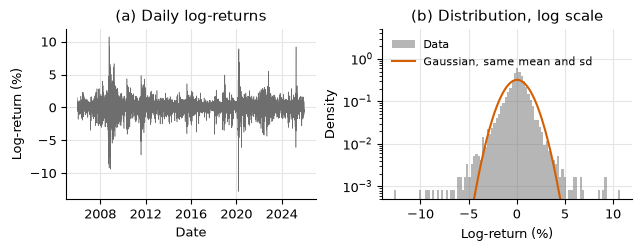

In [8]:
# Figure: (a) the returns over time, (b) their distribution against the Gaussian, on a log scale
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6.3, 2.4))

ax1.plot(y_pct.index, y_pct, color=COLOR_DATA, linewidth=0.4)
ax1.set(title="(a) Daily log-returns", xlabel="Date", ylabel="Log-return (%)")

grid = np.linspace(y_pct.min(), y_pct.max(), 500)
ax2.hist(y_pct, bins=100, density=True, color=COLOR_DATA, alpha=0.5, label="Data")
ax2.plot(grid, stats.norm.pdf(grid, mean, sd), color=COLOR_GAUSS, label="Gaussian, same mean and sd")
ax2.set(title="(b) Distribution, log scale", xlabel="Log-return (%)", ylabel="Density",
        yscale="log", ylim=(5e-4, 5))
ax2.legend(loc="upper left")

save_figure(fig, "data_overview.pdf")
plt.show()

**What we see.**
- **(a)** Calm and turbulent periods alternate: large moves come in clusters (2008–2009, March 2020). Our model will treat the days as independent, so it describes a typical day of the window, not tomorrow given today. This is its main limitation, and notebook 06 tests it.
- **(b)** On a log scale, the Gaussian density is a parabola that falls far too fast: it puts almost no mass where the data's extreme days are. We need a model whose tails are heavier, and whose tail heaviness is learned from the data.

## 4. What we found

In [9]:
# Numbers quoted in the report
print(f"Trading days:      {n:,} ({y.index[0]:%d %B %Y} to {y.index[-1]:%d %B %Y})")
print(f"Mean, sd:          {mean:.3f}%, {sd:.3f}%")
print(f"Worst day:         {y_pct.min():.2f}% on {y_pct.idxmin():%d %B %Y}")
print(f"Best day:          {y_pct.max():.2f}% on {y_pct.idxmax():%d %B %Y}")
print(f"Days beyond 4 sd:  {beyond_4sd} observed, {expected_4sd:.2f} expected if Gaussian")

Trading days:      5,031 (03 January 2006 to 31 December 2025)
Mean, sd:          0.042%, 1.246%
Worst day:         -12.78% on 16 March 2020
Best day:          10.76% on 13 October 2008
Days beyond 4 sd:  36 observed, 0.32 expected if Gaussian


- We have $n$ = 5,031 daily log-returns of the US stock market, 2006–2025, with no missing day.
- Their tails are much heavier than a Gaussian's: a Gaussian model would badly understate the extreme losses that VaR and ES are about.
- Volatility comes in waves; a model with independent days ignores this, and we state it as a limitation.

**Next:** `02_model_and_sampler.ipynb` writes a Student-t model whose tail parameter $\nu$ is learned from these data, and the Metropolis–Hastings sampler that fits it.